# Clinical Trial Data Analysis: Diabetes Medication

## 1. Project Overview

This project investigates the efficacy and safety of a new Type 2 diabetes medication using data from a fictional Phase III clinical trial conducted by PharmaTech.

The dataset contains demographic information, baseline clinical measurements, HbA1c results recorded at multiple time points, treatment group assignments and reported adverse events.

The analysis uses Python to explore patient characteristics, examine changes in HbA1c over the trial period, compare treatment and placebo groups, and investigate adverse events.


## 2. Tools and Libraries

The analysis is conducted using Python in Jupyter Notebook.

The following libraries will be used:

- **pandas:** Data manipulation and analysis.
- **NumPy:** Numerical operations.
- **Matplotlib:** Data visualisation.
- **Seaborn:** Statistical data visualisation.
- **SciPy:** Statistical testing.
- **statsmodels:** Statistical modelling and analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm

## 3. Project Objectives

The objectives of this project are to:

1. Inspect and assess the quality of the clinical trial dataset.
2. Explore patient demographics and baseline characteristics.
3. Investigate changes in HbA1c levels over the 24-month trial period.
4. Compare clinical outcomes between the treatment and placebo groups.
5. Examine differences in individual patient responses.
6. Investigate the frequency and distribution of reported adverse events.
7. Apply appropriate statistical methods to assess differences between treatment groups.
8. Communicate findings, statistical results and limitations clearly.

## 4. Initial Data Inspection and Quality Assessment

In [2]:
df = pd.read_csv('../data/Diabetes_Medication_Clinical_Trial.csv')

In [3]:
df.shape

(1400, 9)

In [4]:
df.head()

,subject_id,group,age,gender,duration_diabetes,initial_hba1c,hba1c,time,adverse_event
0,1,treatment,70,Female,10,8.7,8.7,0,NaN
1,2,placebo,46,Male,19,9.9,9.9,0,Fatigue
2,3,treatment,56,Male,17,8.6,8.6,0,NaN
3,4,treatment,59,Male,19,8.9,8.9,0,Headache
4,5,treatment,68,Male,5,9.1,9.1,0,NaN


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   subject_id         1400 non-null   int64  
 1   group              1400 non-null   str    
 2   age                1400 non-null   int64  
 3   gender             1400 non-null   str    
 4   duration_diabetes  1400 non-null   int64  
 5   initial_hba1c      1400 non-null   float64
 6   hba1c              1400 non-null   float64
 7   time               1400 non-null   int64  
 8   adverse_event      277 non-null    str    
dtypes: float64(2), int64(4), str(3)
memory usage: 118.6 KB


In [6]:
df.describe()

,subject_id,age,duration_diabetes,initial_hba1c,hba1c,time
count,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000
mean,100.500000,55.250000,10.450000,8.465500,7.686029,12.000000
std,57.754936,9.530602,5.805306,0.869367,1.106412,8.002859
min,1.000000,40.000000,1.000000,7.000000,4.700000,0.000000
25%,50.750000,46.000000,5.000000,7.700000,6.980000,4.000000
50%,100.500000,56.000000,11.000000,8.450000,7.700000,12.000000
75%,150.250000,64.000000,16.000000,9.125000,8.500000,20.000000
max,200.000000,70.000000,20.000000,10.000000,10.000000,24.000000


### Descriptive Statistics

The dataset contains 1,400 records for 200 participants. Ages range from 40 to 70 years, with a mean age of 55.25 years. Baseline HbA1c values range from 7.0 to 10.0, with a mean of approximately 8.47.

Recorded HbA1c values have an overall mean of approximately 7.69 across all observations. As participants were measured repeatedly, this figure includes multiple observations per participant and should not be interpreted as an independent patient-level average.

The time variable ranges from 0 to 24. This differs from the 12-month duration stated in the project brief, so the units and study duration require clarification.

In [7]:
df['group'].value_counts()

group
treatment    700
placebo      700
Name: count, dtype: int64

In [8]:
df.groupby('group')['subject_id'].nunique()

group
placebo      100
treatment    100
Name: subject_id, dtype: int64

### Treatment Group Distribution

The dataset contains 200 unique participants, evenly distributed between the two groups:

- Treatment group: 100 participants
- Placebo group: 100 participants

Each participant has seven recorded measurements, giving 700 observations per group and 1,400 records overall. This provides balanced participant numbers for subsequent treatment group comparisons.

In [9]:
pd.crosstab(df['group'], df['gender'])

gender,Female,Male
group,,
placebo,336,364
treatment,427,273


### Gender Distribution

The trial groups contain different gender distributions:

- Placebo: 48 female and 52 male participants.
- Treatment: 61 female and 39 male participants.

Although both groups contain 100 participants, the treatment group has a higher proportion of female participants. This baseline difference should be considered when comparing outcomes between the groups.

In [10]:
df.groupby('group')['age'].describe()

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
placebo,700.0,55.56,9.848094,40.0,45.75,58.0,65.0,70.0
treatment,700.0,54.94,9.198765,40.0,47.00,55.5,63.0,70.0


### Age Distribution

The average age was 55.56 years in the placebo group and 54.94 years in the treatment group. Both groups had an age range of 40–70 years, with similar standard deviations.

These results suggest that the groups have broadly comparable age distributions, although the placebo group has a slightly higher median age.

The descriptive statistics are based on repeated measurements, so the participant-level group sizes remain 100 per group rather than 700.

In [11]:
df.groupby('group')['duration_diabetes'].describe()

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
placebo,700.0,10.46,5.822098,1.0,5.0,10.0,16.0,20.0
treatment,700.0,10.44,5.792610,1.0,5.0,11.0,16.0,20.0


### Diabetes Duration

The mean diabetes duration was 10.46 in the placebo group and 10.44 in the treatment group. Both groups had a range of 1–20, with very similar standard deviations.

These results suggest that the groups were broadly comparable in terms of diabetes duration. The units of this variable should be confirmed before interpreting the values as years.

In [12]:
df.groupby('group')['initial_hba1c'].describe()

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
placebo,700.0,8.399,0.807236,7.0,7.700,8.40,8.925,10.0
treatment,700.0,8.532,0.923143,7.1,7.675,8.55,9.400,10.0


### Baseline HbA1c Comparison

The mean baseline HbA1c was 8.399 in the placebo group and 8.532 in the treatment group. The treatment group therefore started with a slightly higher average HbA1c, with a difference of 0.133.

The groups had broadly similar baseline distributions, although the treatment group showed slightly greater variation.

These baseline differences should be considered when evaluating treatment outcomes. Subsequent analysis will examine changes from each participant's own baseline rather than relying solely on final HbA1c values.

In [13]:
df.groupby('subject_id')['initial_hba1c'].nunique().value_counts()

initial_hba1c
1    200
Name: count, dtype: int64

### Baseline Data Consistency

A consistency check confirmed that all 200 participants had exactly one unique initial HbA1c value across their repeated measurements. This indicates that baseline HbA1c has been recorded consistently for each participant.

In [14]:
df.groupby('subject_id').size().value_counts()

7    200
Name: count, dtype: int64

### Participant Measurement Completeness

A check of the number of records per participant confirmed that all 200 participants have exactly seven measurements recorded. This gives 1,400 records in total and indicates that the dataset is complete in terms of the expected number of observations per participant.

In [15]:
sorted(df['time'].unique())

[np.int64(0),
 np.int64(4),
 np.int64(8),
 np.int64(12),
 np.int64(16),
 np.int64(20),
 np.int64(24)]

### Measurement Time Points

The dataset contains seven distinct measurement time points: 0, 4, 8, 12, 16, 20 and 24. Measurements are recorded at regular four-unit intervals, beginning at baseline.

The dataset therefore covers a time range of 0–24 units. This differs from the 12-month duration stated in the project brief, so the time units and study duration require clarification.

In [16]:
df.groupby('subject_id')['time'].nunique().value_counts()

time
7    200
Name: count, dtype: int64

### Measurement Schedule Consistency

A further check confirmed that all 200 participants have seven unique measurement time points. Each participant therefore has measurements at all seven scheduled intervals, with no missing time points identified.

This confirms consistency in the measurement schedule across participants.

In [17]:
df['adverse_event'].value_counts(dropna=False)

adverse_event
NaN          1123
Fatigue        74
Nausea         71
Headache       68
Dizziness      64
Name: count, dtype: int64

### Adverse Event Data Inspection

The adverse_event column contains 277 recorded entries across four categories:

- Fatigue: 74
- Nausea: 71
- Headache: 68
- Dizziness: 64

There are 1,123 blank entries, representing approximately 80.2% of the dataset. It is not yet clear whether these blanks indicate that no adverse event occurred or whether the information was not recorded. This requires clarification before conducting the safety analysis.

The counts represent recorded observations rather than unique participants.

In [18]:
pd.crosstab(df['group'], df['adverse_event'], dropna=False)

adverse_event,Dizziness,Fatigue,Headache,Nausea,NaN
group,,,,,
placebo,26,40,35,39,560
treatment,38,34,33,32,563


### Adverse Events by Treatment Group

The recorded adverse event counts were similar between the two groups:

- Placebo: 140 recorded observations.
- Treatment: 137 recorded observations.

Dizziness was recorded more frequently in the treatment group (38 compared with 26), while fatigue, headache and nausea were recorded slightly more frequently in the placebo group.

Blank entries represented 80% of placebo records and approximately 80.4% of treatment records. The meaning of these blank entries remains uncertain.

These figures represent recorded observations, not necessarily unique participants. Further investigation is required before drawing conclusions about treatment safety.

In [19]:
df.isnull().sum()

subject_id              0
group                   0
age                     0
gender                  0
duration_diabetes       0
initial_hba1c           0
hba1c                   0
time                    0
adverse_event        1123
dtype: int64

### Missing Data Assessment

A missing-value check confirmed that adverse_event is the only column containing missing values. It has 1,123 missing entries out of 1,400 records (approximately 80.2%).

All other columns are complete, with no missing values identified.

The missing adverse event entries require further investigation to establish whether they represent no reported event or unrecorded information. No values have been changed or removed at this stage.

In [20]:
df.duplicated().sum()

np.int64(0)

### Duplicate Records Assessment

A check for completely duplicated rows identified zero duplicates. This indicates that no records are exact copies of another row across all nine columns.

In [21]:
df.describe(include='all')

,subject_id,group,age,gender,duration_diabetes,initial_hba1c,hba1c,time,adverse_event
count,1400.000000,1400,1400.000000,1400,1400.000000,1400.000000,1400.000000,1400.000000,277
unique,NaN,2,NaN,2,NaN,NaN,NaN,NaN,4
top,NaN,treatment,NaN,Female,NaN,NaN,NaN,NaN,Fatigue
freq,NaN,700,NaN,763,NaN,NaN,NaN,NaN,74
mean,100.500000,NaN,55.250000,NaN,10.450000,8.465500,7.686029,12.000000,NaN
std,57.754936,NaN,9.530602,NaN,5.805306,0.869367,1.106412,8.002859,NaN
min,1.000000,NaN,40.000000,NaN,1.000000,7.000000,4.700000,0.000000,NaN
25%,50.750000,NaN,46.000000,NaN,5.000000,7.700000,6.980000,4.000000,NaN
50%,100.500000,NaN,56.000000,NaN,11.000000,8.450000,7.700000,12.000000,NaN
75%,150.250000,NaN,64.000000,NaN,16.000000,9.125000,8.500000,20.000000,NaN


### Overall Initial Data Quality Assessment

The dataset contains 1,400 records across nine columns, representing 200 participants with seven measurements each. The treatment groups are evenly balanced by participant numbers, and all participants have complete records across the seven measurement time points.

No completely duplicated records or missing values were identified outside the adverse_event column. The adverse_event column contains 1,123 blank entries, the meaning of which requires clarification.

The dataset contains two treatment groups, two gender categories and four recorded adverse event categories. Further clarification is required regarding the units of the time and duration_diabetes variables before interpreting these measurements.

## 5. Data Cleaning and Preparation

In [22]:
df.dtypes

subject_id             int64
group                    str
age                    int64
gender                   str
duration_diabetes      int64
initial_hba1c        float64
hba1c                float64
time                   int64
adverse_event            str
dtype: object

### Data Type Assessment

The data types were reviewed and found to be appropriate for their respective columns. Numerical measurements are stored as integers or floating-point numbers, while categorical variables are stored as strings.

No data type conversions were required at this stage. The subject_id column is retained as an identifier rather than treated as a numerical measurement.

In [23]:
for column in ['group', 'gender', 'adverse_event']:
    print(f"\n{column}:")
    print(df[column].unique())


group:
<ArrowStringArray>
['treatment', 'placebo']
Length: 2, dtype: str

gender:
<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str

adverse_event:
<ArrowStringArray>
[nan, 'Fatigue', 'Headache', 'Dizziness', 'Nausea']
Length: 5, dtype: str


### Categorical Data Assessment

The categorical columns were checked for distinct values and consistency.

- group contains treatment and placebo.
- gender contains Female and Male.
- adverse_event contains four recorded categories: Fatigue, Headache, Dizziness and Nausea.

No inconsistent spelling or capitalisation was identified, so no standardisation was required. Missing adverse event values have been retained pending clarification of their meaning.

In [24]:
df.groupby('time')['adverse_event'].apply(
    lambda x: x.isna().sum()
)

time
0     152
4     161
8     168
12    172
16    155
20    158
24    157
Name: adverse_event, dtype: int64

### Investigation of Missing Adverse Event Values

Missing adverse event entries were examined across the seven measurement time points. The missing values were distributed relatively evenly throughout the trial, ranging from 152 at time 0 to 172 at time 12.

No single time point accounts for a disproportionate concentration of missing entries. However, the reason for the missing values remains unknown, as no supporting dataset documentation was available.

The missing values have been retained without modification.

In [25]:
df.groupby('subject_id')['adverse_event'].apply(
    lambda x: x.isna().sum()
).value_counts().sort_index()

adverse_event
2     3
3     4
4    25
5    47
6    77
7    44
Name: count, dtype: int64

### Missing Adverse Event Values by Participant

An investigation of missing adverse event entries by participant found that all 200 participants had at least two missing entries across their seven measurements.

In particular:
- 77 participants had six missing entries.
- 44 participants had seven missing entries.
- Only seven participants had fewer than four missing entries.

This indicates that missing adverse event information is widespread across participants. The reason for these missing values remains unknown, so they have been retained without modification. This limitation will need to be considered when interpreting the safety analysis.

In [26]:
df.duplicated(subset=['subject_id', 'time']).sum()

np.int64(0)

### Duplicate Participant Measurements

A check for duplicate combinations of subject_id and time identified zero duplicates. Each participant therefore has only one record for each measurement time point.

In [27]:
df['hba1c'].describe()

count    1400.000000
mean        7.686029
std         1.106412
min         4.700000
25%         6.980000
50%         7.700000
75%         8.500000
max        10.000000
Name: hba1c, dtype: float64

### HbA1c Value Assessment

The hba1c column contains 1,400 complete numerical observations, ranging from 4.7 to 10.0. The mean is approximately 7.69 and the median is 7.70.

No immediately obvious implausible values were identified from the descriptive statistics. The values will be retained for further analysis, with their clinical interpretation considered in context.

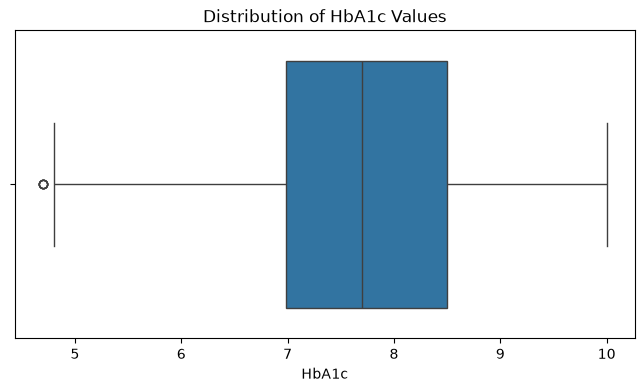

In [28]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df['hba1c'])

plt.title('Distribution of HbA1c Values')
plt.xlabel('HbA1c')
plt.show()

### HbA1c Outlier Assessment

A box plot was used to examine the distribution of HbA1c measurements. One potential low-end outlier was visible, just below 5. The lower whisker was also slightly longer than the upper whisker, suggesting somewhat greater spread towards the lower end of the distribution.

The potential outlier was retained because there is currently no evidence that it represents an incorrect measurement. Further investigation would be required before considering any changes.

In [29]:
df.loc[
    df['hba1c'] == df['hba1c'].min(),
    ['subject_id', 'group', 'initial_hba1c', 'hba1c', 'time']
]

,subject_id,group,initial_hba1c,hba1c,time
1237,38,treatment,7.1,4.7,24
1238,39,treatment,7.1,4.7,24
1280,81,treatment,7.1,4.7,24
1333,134,treatment,7.1,4.7,24
1351,152,treatment,7.1,4.7,24


In [30]:
df.loc[
    df['subject_id'].isin([38, 39, 81, 134, 152]),
    ['subject_id', 'group', 'hba1c', 'time']
].sort_values(['subject_id', 'time'])

,subject_id,group,hba1c,time
37,38,treatment,7.1,0
237,38,treatment,6.7,4
437,38,treatment,6.3,8
637,38,treatment,5.9,12
837,38,treatment,5.5,16
1037,38,treatment,5.1,20
1237,38,treatment,4.7,24
38,39,treatment,7.1,0
238,39,treatment,6.7,4
438,39,treatment,6.3,8


Further investigation identified five participants in the treatment group with the lowest HbA1c measurement (4.7) at time point 24. All five participants had identical baseline measurements (7.1) and identical reductions of 0.4 at each subsequent measurement.

Although the values are internally consistent, the identical pattern across five participants raises a potential data-quality concern. The observations were retained, as there is insufficient evidence to establish that they are incorrect.

In [31]:
treatment_patterns = (
    df[df['group'] == 'treatment']
    .pivot(index='subject_id', columns='time', values='hba1c')
)

treatment_patterns.head()

time,0,4,8,12,16,20,24
subject_id,,,,,,,
1,8.7,8.3,7.9,7.5,7.1,6.7,6.3
3,8.6,8.2,7.8,7.4,7.0,6.6,6.2
4,8.9,8.5,8.1,7.7,7.3,6.9,6.5
5,9.1,8.7,8.3,7.9,7.5,7.1,6.7
7,8.9,8.5,8.1,7.7,7.3,6.9,6.5


In [32]:
treatment_changes = treatment_patterns.diff(axis=1)

treatment_changes.head()

time,0,4,8,12,16,20,24
subject_id,,,,,,,
1,NaN,-0.4,-0.4,-0.4,-0.4,-0.4,-0.4
3,NaN,-0.4,-0.4,-0.4,-0.4,-0.4,-0.4
4,NaN,-0.4,-0.4,-0.4,-0.4,-0.4,-0.4
5,NaN,-0.4,-0.4,-0.4,-0.4,-0.4,-0.4
7,NaN,-0.4,-0.4,-0.4,-0.4,-0.4,-0.4


In [33]:
treatment_changes.stack().value_counts()

-0.4    384
-0.4    192
-0.4     24
Name: count, dtype: int64

In [34]:
treatment_changes.stack().round(6).value_counts()

-0.4    600
Name: count, dtype: int64

Further investigation of all 100 treatment participants identified an identical pattern of HbA1c reduction. All 600 consecutive measurement changes were -0.4 when rounded to six decimal places.

This unusually consistent pattern suggests the dataset may contain artificially generated or simplified measurements rather than the variation typically expected in a clinical trial. The data was retained, but this limitation will be considered when interpreting treatment efficacy.

## 6. Exploratory Data Analysis

In [35]:
patients = df.drop_duplicates(subset='subject_id')

patients.shape

(200, 9)

### 6.1 Patient Demographics and Baseline Characteristics

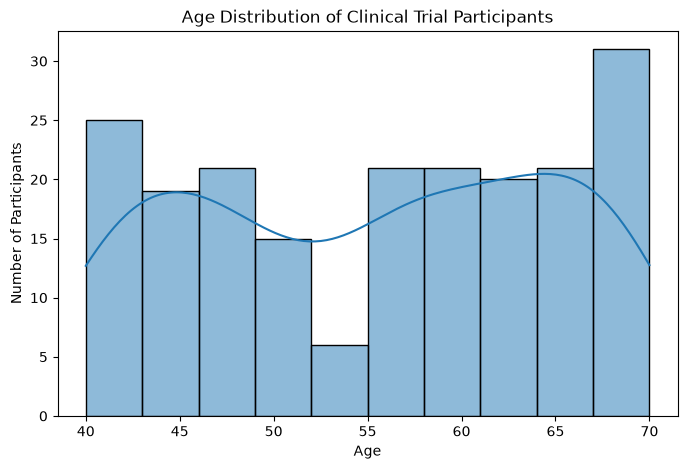

In [36]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=patients,
    x='age',
    bins=10,
    kde=True
)

plt.title('Age Distribution of Clinical Trial Participants')
plt.xlabel('Age')
plt.ylabel('Number of Participants')

plt.show()

#### Age Distribution

The participants' ages ranged from 40 to 70. The distribution showed a gradual decline towards approximately age 50, followed by an increase. Participant numbers remained relatively consistent through much of the 55–65 age range, with the highest frequency observed towards the upper end of the age range.

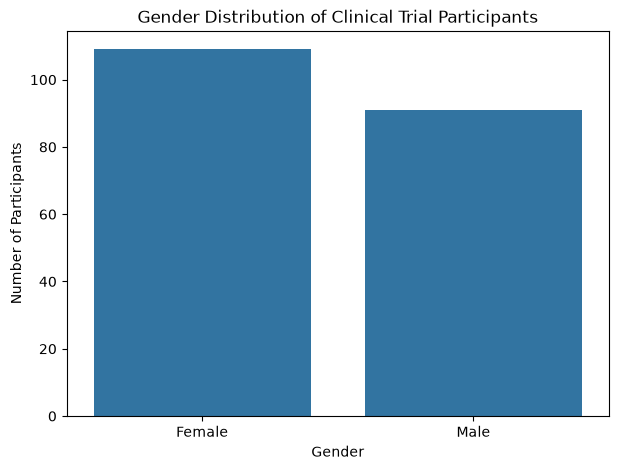

In [37]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=patients,
    x='gender'
)

plt.title('Gender Distribution of Clinical Trial Participants')
plt.xlabel('Gender')
plt.ylabel('Number of Participants')

plt.show()

In [38]:
patients['gender'].value_counts()

gender
Female    109
Male       91
Name: count, dtype: int64

#### Gender Distribution

The trial included 109 female participants (54.5%) and 91 male participants (45.5%). The gender distribution was relatively balanced, although females accounted for a slightly higher proportion of participants.

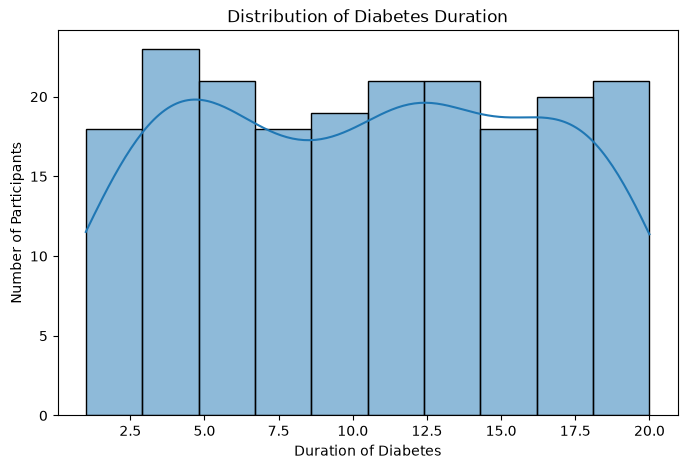

In [39]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=patients,
    x='duration_diabetes',
    bins=10,
    kde=True
)

plt.title('Distribution of Diabetes Duration')
plt.xlabel('Duration of Diabetes')
plt.ylabel('Number of Participants')

plt.show()

In [40]:
patients['duration_diabetes'].describe()

count    200.000000
mean      10.450000
std        5.817795
min        1.000000
25%        5.000000
50%       11.000000
75%       16.000000
max       20.000000
Name: duration_diabetes, dtype: float64

#### Duration of Diabetes

The recorded duration of diabetes ranged from 1 to 20, with a mean of 10.45 and a median of 11. The middle 50% of participants had recorded values between 5 and 16. The mean and median were relatively close, suggesting a broadly balanced distribution. The units for this variable were not specified in the dataset documentation.

#### Demographic Summary

The trial included 200 participants aged between 40 and 70. There were slightly more female participants (109) than male participants (91). Recorded diabetes duration ranged from 1 to 20, with a mean of 10.45.

These findings provide an overview of the trial population. The next stage examines whether the treatment and placebo groups had comparable characteristics at baseline.

### 6.2 Baseline Comparison Between Treatment Groups

In [41]:
patients.groupby('group')[
    ['age', 'duration_diabetes', 'initial_hba1c']
].mean()

,age,duration_diabetes,initial_hba1c
group,,,
placebo,55.56,10.46,8.399
treatment,54.94,10.44,8.532


#### Comparison of Numerical Baseline Characteristics

The average age, diabetes duration and initial HbA1c were compared between the treatment and placebo groups.

The average age was 55.56 in the placebo group and 54.94 in the treatment group. Mean diabetes duration was almost identical at 10.46 and 10.44 respectively. Initial HbA1c was slightly higher in the treatment group (8.532) than in the placebo group (8.399).

Overall, the groups showed similar average baseline characteristics, although the treatment group had a slightly higher initial HbA1c.

In [42]:
pd.crosstab(
    patients['group'],
    patients['gender']
)

gender,Female,Male
group,,
placebo,48,52
treatment,61,39


#### Comparison of Gender Distribution

The placebo group included 48 female participants (48%) and 52 male participants (52%). The treatment group included 61 female participants (61%) and 39 male participants (39%).

The placebo group had a relatively balanced gender distribution, whereas the treatment group had a higher proportion of female participants. This difference should be considered when interpreting the treatment outcomes.

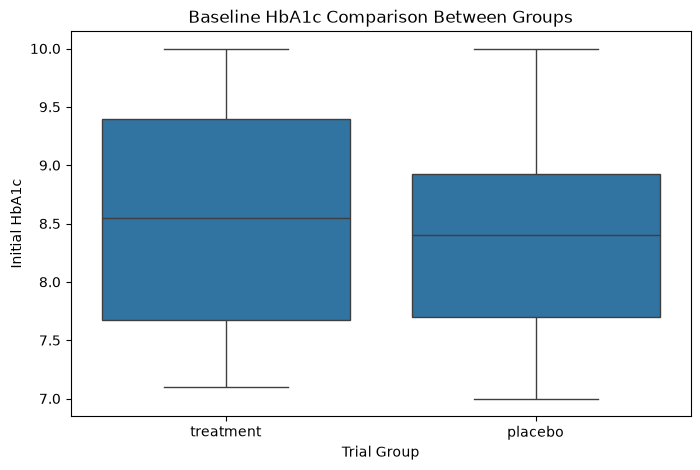

In [43]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=patients,
    x='group',
    y='initial_hba1c'
)

plt.title('Baseline HbA1c Comparison Between Groups')
plt.xlabel('Trial Group')
plt.ylabel('Initial HbA1c')

plt.show()

#### Baseline HbA1c Distribution

A box plot was used to compare the distribution of initial HbA1c measurements between the treatment and placebo groups.

The median values were close, at approximately 8.5. The lower quartiles were also similar, while the upper quartile was higher in the treatment group. This suggests a slightly greater spread towards higher baseline HbA1c values in the treatment group. No potential outliers were identified in either group.

### 6.3 HbA1c Changes Over Time

In [44]:
mean_hba1c = df.groupby(
    ['group', 'time']
)['hba1c'].mean().reset_index()

mean_hba1c

,group,time,hba1c
0,placebo,0,8.3990
1,placebo,4,8.2790
2,placebo,8,8.1590
3,placebo,12,8.0390
4,placebo,16,7.9190
5,placebo,20,7.8000
6,placebo,24,7.6854
7,treatment,0,8.5320
8,treatment,4,8.1320
9,treatment,8,7.7320


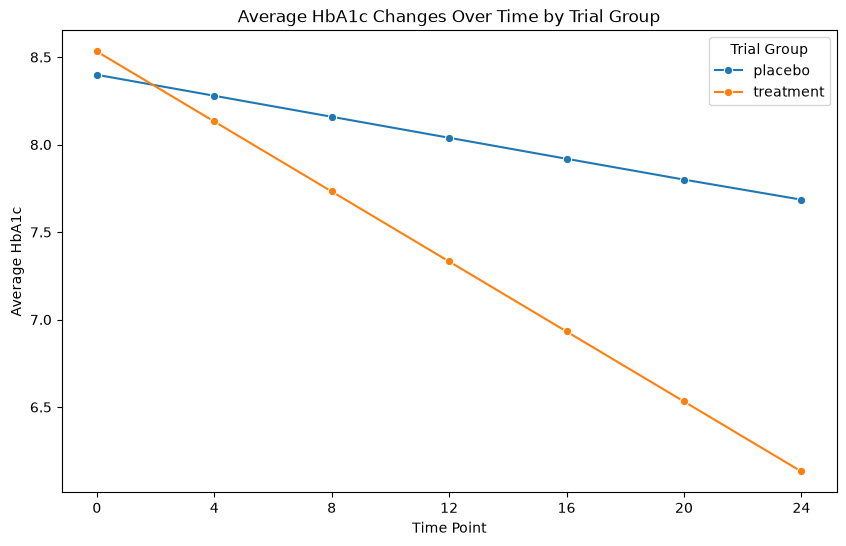

In [66]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=mean_hba1c,
    x='time',
    y='hba1c',
    hue='group',
    marker='o'
)

plt.title('Average HbA1c Changes Over Time by Trial Group')
plt.xlabel('Time Point')
plt.ylabel('Average HbA1c')
plt.xticks(sorted(df['time'].unique()))
plt.legend(title='Trial Group')

plt.savefig('../outputs/average_hba1c_over_time.png', dpi=300, bbox_inches='tight')
plt.show()

#### HbA1c Trends Over Time

A line chart was used to compare average HbA1c measurements across the treatment and placebo groups.

Both groups showed a downward trend in average HbA1c over the trial period. However, the treatment group experienced a considerably steeper reduction than the placebo group. The treatment group's average HbA1c decreased consistently at each measurement interval, while the placebo group showed a smaller overall reduction.

The difference between the groups increased over time, suggesting a greater reduction in HbA1c among participants receiving the medication. However, the unusually consistent treatment-group trend should be considered when interpreting these findings.

### 6.4 Comparing Treatment Efficacy

In [46]:
patient_changes = df.pivot(
    index='subject_id',
    columns='time',
    values='hba1c'
)

patient_changes.head()

time,0,4,8,12,16,20,24
subject_id,,,,,,,
1,8.7,8.30,7.90,7.50,7.10,6.7,6.30
2,9.9,9.78,9.66,9.54,9.42,9.3,9.18
3,8.6,8.20,7.80,7.40,7.00,6.6,6.20
4,8.9,8.50,8.10,7.70,7.30,6.9,6.50
5,9.1,8.70,8.30,7.90,7.50,7.1,6.70


In [47]:
patient_changes['hba1c_change'] = (
    patient_changes[24] - patient_changes[0]
)

patient_changes.head()

time,0,4,8,12,16,20,24,hba1c_change
subject_id,,,,,,,,
1,8.7,8.30,7.90,7.50,7.10,6.7,6.30,-2.40
2,9.9,9.78,9.66,9.54,9.42,9.3,9.18,-0.72
3,8.6,8.20,7.80,7.40,7.00,6.6,6.20,-2.40
4,8.9,8.50,8.10,7.70,7.30,6.9,6.50,-2.40
5,9.1,8.70,8.30,7.90,7.50,7.1,6.70,-2.40


In [48]:
patient_changes = patient_changes.join(
    patients.set_index('subject_id')['group']
)

patient_changes.head()

,0,4,8,12,16,20,24,hba1c_change,group
subject_id,,,,,,,,,
1,8.7,8.30,7.90,7.50,7.10,6.7,6.30,-2.40,treatment
2,9.9,9.78,9.66,9.54,9.42,9.3,9.18,-0.72,placebo
3,8.6,8.20,7.80,7.40,7.00,6.6,6.20,-2.40,treatment
4,8.9,8.50,8.10,7.70,7.30,6.9,6.50,-2.40,treatment
5,9.1,8.70,8.30,7.90,7.50,7.1,6.70,-2.40,treatment


In [49]:
patient_changes.groupby('group')['hba1c_change'].describe()

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
placebo,100.0,-0.7136,2.993326e-02,-0.72,-0.72,-0.72,-0.72,-0.5
treatment,100.0,-2.4000,4.463264e-16,-2.40,-2.40,-2.40,-2.40,-2.4


The treatment group showed a greater average reduction in HbA1c
(-2.40) compared with the placebo group (-0.714).

The treatment group had virtually no variation in individual
changes, whereas the placebo group showed a small amount of
variation. The identical treatment response across all
participants suggests the dataset may be artificially generated
or simplified, which should be considered when interpreting
the findings.

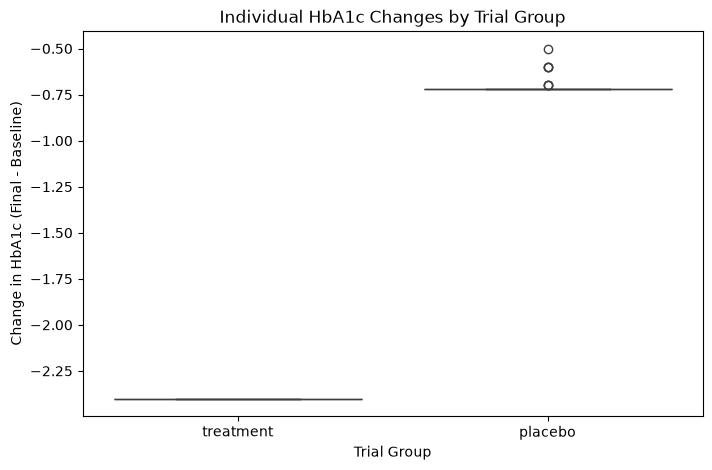

In [67]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=patient_changes,
    x='group',
    y='hba1c_change'
)

plt.title('Individual HbA1c Changes by Trial Group')
plt.xlabel('Trial Group')
plt.ylabel('Change in HbA1c (Final - Baseline)')

plt.savefig('../outputs/hba1c_change_by_group.png', dpi=300, bbox_inches='tight')
plt.show()

The boxplot showed very little variation in HbA1c changes within
either group. The treatment group's values were identical,
causing its box to collapse into a single line. Three outliers
were visible in the placebo group, indicating a small number of
participants with changes outside the typical range.

The unusually consistent treatment results should be considered
when interpreting the findings.

### 6.5 Patient-Level Treatment Responses

In [51]:
patient_changes.groupby('group')['hba1c_change'].agg(
    ['min', 'max', 'mean', 'std']
)

,min,max,mean,std
group,,,,
placebo,-0.72,-0.5,-0.7136,2.993326e-02
treatment,-2.40,-2.4,-2.4000,4.440892e-16


The patient-level analysis showed that HbA1c changes in the
placebo group ranged from -0.72 to -0.50, indicating a small
degree of variation between participants.

All participants in the treatment group showed an identical
reduction of -2.40. This lack of variation is unusual in real
clinical trial data and should be considered when interpreting
the results.

Overall, the treatment group demonstrated a greater reduction
in HbA1c than the placebo group in this dataset.

In [52]:
patient_trends = df.copy()

patient_trends['change_from_baseline'] = (
    patient_trends['hba1c'] - patient_trends['initial_hba1c']
)

patient_trends.groupby(['group', 'time'])['change_from_baseline'].mean().unstack()

time,0,4,8,12,16,20,24
group,,,,,,,
placebo,0.0,-0.12,-0.24,-0.36,-0.48,-0.599,-0.7136
treatment,0.0,-0.40,-0.80,-1.20,-1.60,-2.000,-2.4000


The analysis showed that both groups experienced a reduction
in average HbA1c at each recorded time point.

The placebo group showed a gradual reduction, reaching -0.7136
at the final recorded time point. The treatment group showed
a larger reduction, reaching -2.40.

The treatment group's average HbA1c decreased by exactly 0.40
at every interval. This highly consistent pattern reinforces
the concern that the dataset may have been artificially
generated or simplified.

The results indicate a greater observed reduction in the
treatment group, although the limitations of the dataset must
be considered.

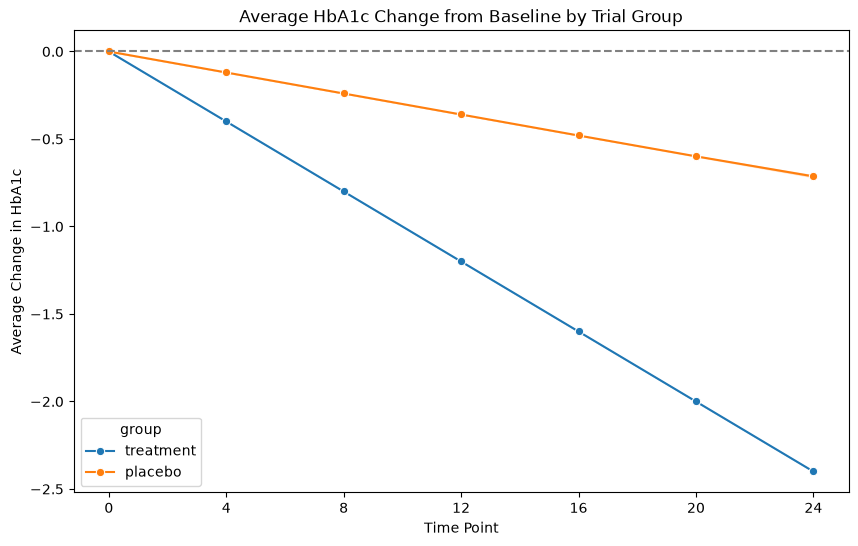

In [69]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=patient_trends,
    x='time',
    y='change_from_baseline',
    hue='group',
    marker='o',
    estimator='mean'
)

plt.title('Average HbA1c Change from Baseline by Trial Group')
plt.xlabel('Time Point')
plt.ylabel('Average Change in HbA1c')
plt.xticks(sorted(df['time'].unique()))
plt.axhline(0, linestyle='--', color='grey')

plt.savefig('../outputs/patient_level_hba1c_response.png', dpi=300, bbox_inches='tight')
plt.show()

The line chart showed a downward trend in average HbA1c
changes for both groups.

The treatment group had a much steeper downward gradient,
indicating a larger reduction over time compared with the
placebo group. The gap between the two lines increased at
each time point.

This supports the earlier finding that the treatment group
experienced a greater reduction in HbA1c. However, the
unusually consistent treatment response remains an
important limitation of the dataset.

### 6.6 Adverse Events and Safety Analysis

In [54]:
df['adverse_event'].value_counts()

adverse_event
Fatigue      74
Nausea       71
Headache     68
Dizziness    64
Name: count, dtype: int64

Four types of adverse events were recorded: fatigue (74),
nausea (71), headache (68) and dizziness (64).

Fatigue was the most frequently recorded event, while
dizziness was the least frequent. The counts were relatively
similar across all four categories.

These figures represent recorded entries rather than
necessarily unique participants. The high proportion of
missing adverse-event data also limits the interpretation
of these findings.

In [55]:
pd.crosstab(
    df['group'],
    df['adverse_event']
)

adverse_event,Dizziness,Fatigue,Headache,Nausea
group,,,,
placebo,26,40,35,39
treatment,38,34,33,32


A comparison of recorded adverse events between the groups
showed 140 entries in the placebo group and 137 in the
treatment group.

Dizziness was recorded more frequently in the treatment
group (38 compared with 26). Fatigue, headache and nausea
were recorded slightly more frequently in the placebo group.

The overall number of recorded entries was similar between
the groups. However, these figures represent event records
rather than unique participants. The substantial amount of
missing adverse-event data prevents reliable conclusions
about comparative safety.

In [56]:
patients_with_events = (
    df.groupby('subject_id')['adverse_event']
    .count()
    .gt(0)
)

patients_with_events.sum()

np.int64(156)

In [57]:
patient_event_summary = (
    df.groupby(['subject_id', 'group'])['adverse_event']
    .count()
    .reset_index(name='recorded_events')
)

patient_event_summary['had_event'] = (
    patient_event_summary['recorded_events'] > 0
)

patient_event_summary.groupby('group')['had_event'].sum()

group
placebo      80
treatment    76
Name: had_event, dtype: int64

At participant level, 80 of the 100 placebo participants
(80%) and 76 of the 100 treatment participants (76%) had
at least one recorded adverse event.

The proportions were similar between the groups. However,
the absence of a recorded event cannot be interpreted as
evidence that a participant experienced no adverse events,
because of the substantial missing data.

Consequently, these findings do not establish whether the
medication was safer or less safe than the placebo.

In [58]:
patient_event_summary.groupby('group')['recorded_events'].describe()

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
placebo,100.0,1.40,1.137070,0.0,1.0,1.0,2.0,5.0
treatment,100.0,1.37,1.088554,0.0,1.0,1.0,2.0,5.0


The participant-level summary showed that the average number
of recorded adverse-event entries was similar in the placebo
group (1.40) and treatment group (1.37).

Both groups had a median of one recorded entry per participant,
with a maximum of five. The standard deviations were also
similar.

Overall, the recorded adverse-event patterns were comparable
between the groups. However, the substantial missing data
means that these findings cannot establish the comparative
safety of the medication.

## 7. Statistical Analysis

### 7.1 Statistical Test Selection

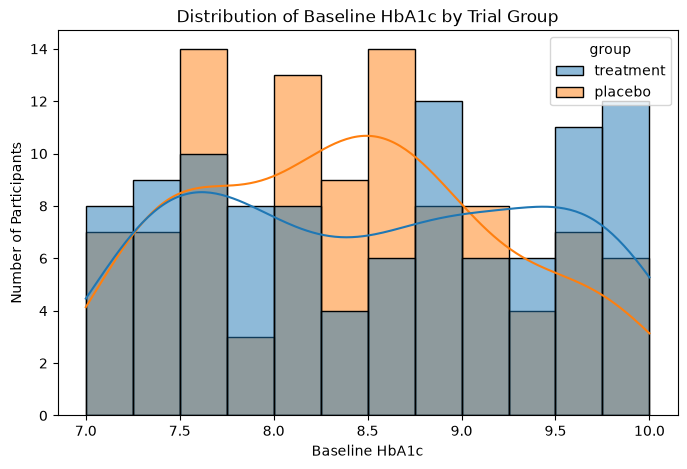

In [71]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=patients,
    x='initial_hba1c',
    hue='group',
    bins=12,
    kde=True
)

plt.title('Distribution of Baseline HbA1c by Trial Group')
plt.xlabel('Baseline HbA1c')
plt.ylabel('Number of Participants')

plt.savefig('../outputs/baseline_hba1c_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

The baseline HbA1c distributions showed considerable overlap
between the treatment and placebo groups. The placebo
distribution appeared more concentrated around the middle,
while the treatment distribution extended further towards
both lower and higher values.

The distributions were not identical, so a statistical test
was used to investigate whether the difference in group
means was statistically significant.

### 7.2 Treatment Group Comparisons

In [60]:
treatment_baseline = patients.loc[
    patients['group'] == 'treatment', 'initial_hba1c'
]

placebo_baseline = patients.loc[
    patients['group'] == 'placebo', 'initial_hba1c'
]

stats.ttest_ind(
    treatment_baseline,
    placebo_baseline,
    equal_var=False
)

TtestResult(statistic=np.float64(1.0798943350399615), pvalue=np.float64(0.28152623389773873), df=np.float64(194.53966287379356))

#### Baseline HbA1c Statistical Comparison

Welch's independent samples t-test was used to compare
baseline HbA1c between the treatment and placebo groups.

The test produced a t-statistic of 1.080 and a p-value
of 0.282.

As the p-value was greater than the significance level
of 0.05, the null hypothesis was not rejected. There was
insufficient statistical evidence of a significant
difference in mean baseline HbA1c between the groups.

This suggests that the groups had broadly similar
baseline HbA1c levels before the treatment period.

In [61]:
treatment_change = patient_changes.loc[
    patient_changes['group'] == 'treatment', 'hba1c_change'
]

placebo_change = patient_changes.loc[
    patient_changes['group'] == 'placebo', 'hba1c_change'
]

stats.ttest_ind(
    treatment_change,
    placebo_change,
    equal_var=False
)

C:\Users\gwynne-jones\AppData\Local\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


TtestResult(statistic=np.float64(-563.3866979513901), pvalue=np.float64(2.2411857733172433e-175), df=np.float64(99.0))

#### HbA1c Change Statistical Comparison

Welch's independent samples t-test was used to compare
the change in HbA1c between the treatment and placebo
groups, using each participant's change from baseline
to the final recorded time point.

The test produced a t-statistic of -563.387 and a
p-value of 2.24 × 10⁻¹⁷⁵.

The p-value was considerably below the significance
level of 0.05, so the null hypothesis was rejected.
There was a statistically significant difference in
mean HbA1c change between the groups.

However, the treatment group showed an identical
reduction of 2.4 for all 100 participants. This
unusually uniform pattern caused a precision warning
during the statistical calculation and raises
concerns about the realism of the dataset.

The statistical result should therefore be interpreted
with caution and not treated as reliable evidence of
clinical effectiveness.

In [62]:
treatment_patients = patients.loc[
    patients['group'] == 'treatment', 'subject_id'
]

treatment_start = patient_changes.loc[
    treatment_patients, 0
]

treatment_end = patient_changes.loc[
    treatment_patients, 24
]

In [63]:
stats.ttest_rel(
    treatment_start,
    treatment_end
)

C:\Users\gwynne-jones\AppData\Local\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:431: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  return hypotest_fun_in(*args, **kwds)


TtestResult(statistic=np.float64(5.3772300611900376e+16), pvalue=np.float64(0.0), df=np.int64(99))

#### Paired t-test: Treatment Group

A paired t-test was used to compare baseline and final
recorded HbA1c measurements for the 100 participants
in the treatment group.

The test produced a t-statistic of approximately
5.38 × 10¹⁶ and a p-value displayed as 0.0.

The result indicates a statistically significant
change in HbA1c between the two measurements.

However, the calculation generated a precision-loss
warning because all participants had identical
reductions in HbA1c. This resulted in virtually no
variation in the individual changes and an unusually
large test statistic.

The result should therefore be interpreted with
considerable caution.

In [64]:
placebo_patients = patients.loc[
    patients['group'] == 'placebo', 'subject_id'
]

placebo_start = patient_changes.loc[
    placebo_patients, 0
]

placebo_end = patient_changes.loc[
    placebo_patients, 24
]

In [65]:
stats.ttest_rel(
    placebo_start,
    placebo_end
)

TtestResult(statistic=np.float64(238.3970277858824), pvalue=np.float64(1.982168609494244e-138), df=np.int64(99))

#### Paired t-test: Placebo Group

A paired t-test was used to compare baseline and final
recorded HbA1c measurements for the 100 participants
in the placebo group.

The test produced a t-statistic of 238.397 and a
p-value of 1.98 × 10⁻¹³⁸.

As the p-value was below 0.05, the null hypothesis
was rejected. There was statistically significant
evidence of a change in HbA1c within the placebo group.

The mean reduction was approximately 0.714, compared
with 2.400 in the treatment group.

Both groups experienced reductions, although the
treatment group showed a substantially larger change.

### 7.3 Interpretation of Statistical Results

### Interpretation of Statistical Findings

The statistical analysis found that both the treatment and
placebo groups experienced statistically significant
reductions in HbA1c between baseline and the final
recorded time point.

However, the reduction was substantially greater in
the treatment group (2.400) than in the placebo group
(0.714).

Comparing the changes between groups is important
because an improvement within the treatment group
alone does not establish that the medication was
responsible. The placebo group provides a comparison
to help assess whether the treatment group experienced
an additional reduction.

The between-group comparison identified a statistically
significant difference. However, the unusually uniform
treatment responses and precision warnings mean that
this result must be interpreted with considerable
caution.

## 8. Key Findings and Limitations

### 8.1 Key Findings

The exploratory data analysis and statistical testing identified
the following key findings:

1. **Participants:** The dataset contained 200 participants,
   divided equally between the treatment and placebo groups.

2. **Baseline characteristics:** The groups had similar
   average ages, diabetes duration and baseline HbA1c levels,
   although their gender distributions differed.

3. **HbA1c trends:** Both groups experienced reductions in
   average HbA1c across the recorded time points.

4. **Treatment comparison:** The treatment group showed a
   greater average reduction (2.400) than the placebo group
   (0.714). Statistical testing identified a significant
   difference between the groups.

5. **Adverse events:** There were 277 recorded adverse-event
   entries, with broadly similar numbers in each group.
   However, extensive missing data limits interpretation.

The analysis identified several limitations that should be
considered when interpreting the findings:

1. **Unusually consistent treatment responses:** All 100
   treatment participants showed exactly the same HbA1c
   reduction of 2.4. This suggests the dataset may have
   been artificially generated or simplified.

2. **Missing adverse-event data:** 1,123 of the 1,400
   records (80.2%) had no adverse-event entry. It is
   unclear whether these represent no adverse event or
   missing information, limiting the safety analysis.

3. **Gender imbalance:** The treatment group contained
   61 females and 39 males, compared with 48 females
   and 52 males in the placebo group.

4. **Unclear time units:** The project brief refers to
   a 12-month trial, but the dataset contains time
   points from 0 to 24. The units require clarification.

5. **Unspecified measurement units:** The dataset does
   not clearly specify the units for HbA1c or diabetes
   duration.

6. **Limitations of the dataset:** The unusually regular
   patterns and missing information restrict the
   reliability and real-world interpretation of the
   findings.

## 9. Conclusion

## 9. Conclusion

This project used Python to explore clinical trial data
for a fictional Type 2 diabetes medication, investigating
changes in HbA1c and recorded adverse events across
treatment and placebo groups.

The analysis found that both groups experienced
reductions in average HbA1c over the recorded trial
period. However, the treatment group showed a
substantially greater average reduction (2.400)
compared with the placebo group (0.714). Statistical
testing identified a significant difference between
the groups.

The analysis of adverse events found broadly similar
numbers of recorded events across the two groups.
However, the high proportion of missing adverse-event
records meant that no reliable conclusions about
medication safety could be drawn.

Several limitations affected the interpretation of
the findings, particularly the identical HbA1c
reductions across all treatment participants, the
missing adverse-event information and the uncertainty
surrounding the trial's time units.

Overall, the analysis demonstrated how Python can
be used to explore clinical data, identify patterns,
compare groups and apply statistical tests. It also
highlighted the importance of data quality, appropriate
statistical methods and critical interpretation when
working with real-world-style datasets.

The results suggest a greater reduction in HbA1c in
the treatment group, but the limitations mean that
they should not be treated as reliable evidence of
clinical effectiveness or safety.